
# Experiment 01 — Learning Rate Analysis

## Research Question

How does the learning rate affect convergence speed,
optimization stability, and validation performance
of a NumPy-based MLP trained on MNIST?

## Experimental Setup

| Hyperparameter | Value |
|---|---|
| Architecture | 784 → 128 (ReLU) → 10 (Softmax) |
| Optimizer | Mini-batch SGD |
| Epochs | 10 |
| Batch size | 64 |
| Seed | 42 |
| Training samples | 55,000 |
| Validation samples | 5,000 |
| Learning rates | 0.0001, 0.001, 0.01, 0.1, 1.0 |

Only the learning rate is varied across experiments.

## Initial Hypotheses

- A learning rate of 0.1 may achieve the lowest validation loss
  within 10 epochs by enabling faster optimization.
- A learning rate of 0.01 may converge more slowly.
- A learning rate of 1.0 may cause training instability
  due to excessively large parameter updates.


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXPERIMENTS_DIR = Path("../experiments/learning_rate")

assert EXPERIMENTS_DIR.exists(), (
    f"Experiment directory not found: {EXPERIMENTS_DIR}"
)

In [2]:
experiment_dirs = sorted(
    path
    for path in EXPERIMENTS_DIR.iterdir()
    if path.is_dir()
)

print(f"Found {len(experiment_dirs)} experiment directories:")

for path in experiment_dirs:
    print(" -", path.name)

Found 5 experiment directories:
 - mlp_lr0.0001_seed42_20261115_094545_634929
 - mlp_lr0.001_seed42_20261115_094630_526445
 - mlp_lr0.01_seed42_20261115_094714_209687
 - mlp_lr0.1_seed42_20261115_095118_062809
 - mlp_lr1.0_seed42_20261115_095144_654388


In [3]:
experiments = []

for experiment_dir in experiment_dirs:
    with open(experiment_dir / "config.json", encoding="utf-8") as f:
        config = json.load(f)

    with open(experiment_dir / "metrics.json", encoding="utf-8") as f:
        metrics = json.load(f)

    with open(experiment_dir / "history.json", encoding="utf-8") as f:
        history = json.load(f)

    experiments.append({
        "name": experiment_dir.name,
        "config": config,
        "metrics": metrics,
        "history": history,
    })

print(f"Loaded {len(experiments)} experiments.")

Loaded 5 experiments.


In [4]:
rows = []

for experiment in experiments:
    config = experiment["config"]
    metrics = experiment["metrics"]

    rows.append({
        "Learning Rate": config["learning_rate"],
        "Validation Accuracy (%)": metrics["validation_accuracy"] * 100,
        "Validation Loss": metrics["validation_loss"],
        "Training Loss": metrics["final_training_loss"],
        "Training Time (s)": metrics["training_time_seconds"],
    })

results_df = (
    pd.DataFrame(rows)
    .sort_values("Learning Rate")
    .reset_index(drop=True)
)

display(results_df.round(4))

,Learning Rate,Validation Accuracy (%),Validation Loss,Training Loss,Training Time (s)
0,0.0001,64.20,1.6065,1.6045,13.4291
1,0.0010,86.82,0.5040,0.4887,15.8371
2,0.0100,92.50,0.2528,0.2280,31.1510
3,0.1000,97.26,0.0950,0.0546,16.0897
4,1.0000,96.74,0.1623,0.0504,14.2711


## Training Loss Comparison

This section examines how different learning rates affect
the optimization process over the first 10 epochs.

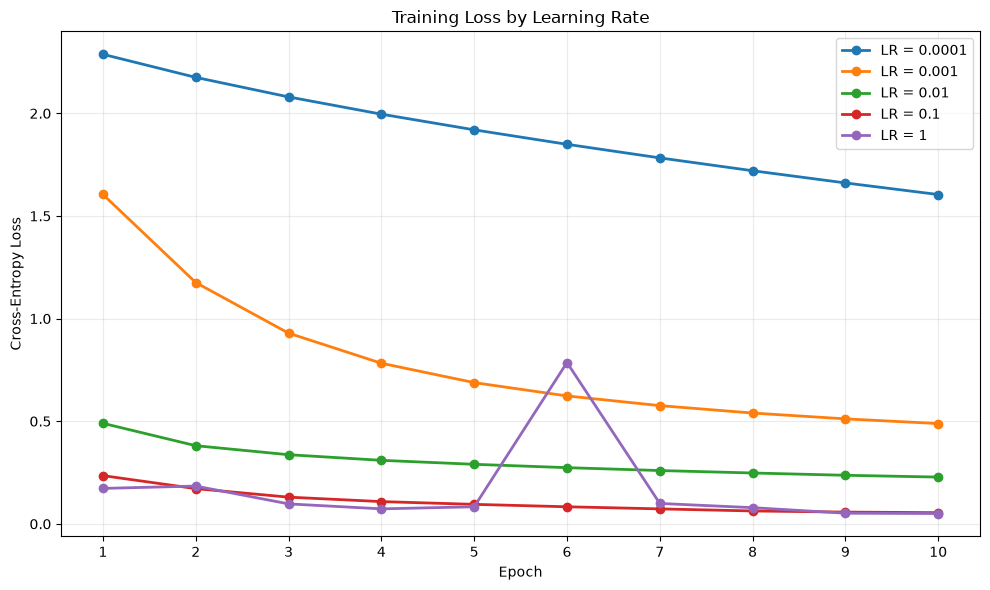

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

for experiment in experiments:
    lr = experiment["config"]["learning_rate"]
    losses = experiment["history"]["train_loss"]
    epochs = np.arange(1, len(losses) + 1)

    ax.plot(
        epochs,
        losses,
        marker="o",
        linewidth=2,
        label=f"LR = {lr:g}",
    )

ax.set(
    title="Training Loss by Learning Rate",
    xlabel="Epoch",
    ylabel="Cross-Entropy Loss",
)

ax.set_xticks(np.arange(1, 11))
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
plt.show()


## Validation Loss Comparison

Training loss measures how well a model fits the training
data, whereas validation loss evaluates its performance
on unseen data.

By comparing validation loss curves across different
learning rates, we can investigate how the learning rate
affects not only convergence speed but also the model's
ability to generalize.

In particular, we examine:

- How quickly each learning rate reduces validation loss.
- Whether validation loss decreases consistently or fluctuates.
- Which learning rate achieves the lowest validation loss
  within the fixed training budget of 10 epochs.

A lower validation loss indicates better predictive
performance on the validation dataset, but does not
guarantee equally strong performance on all unseen data.


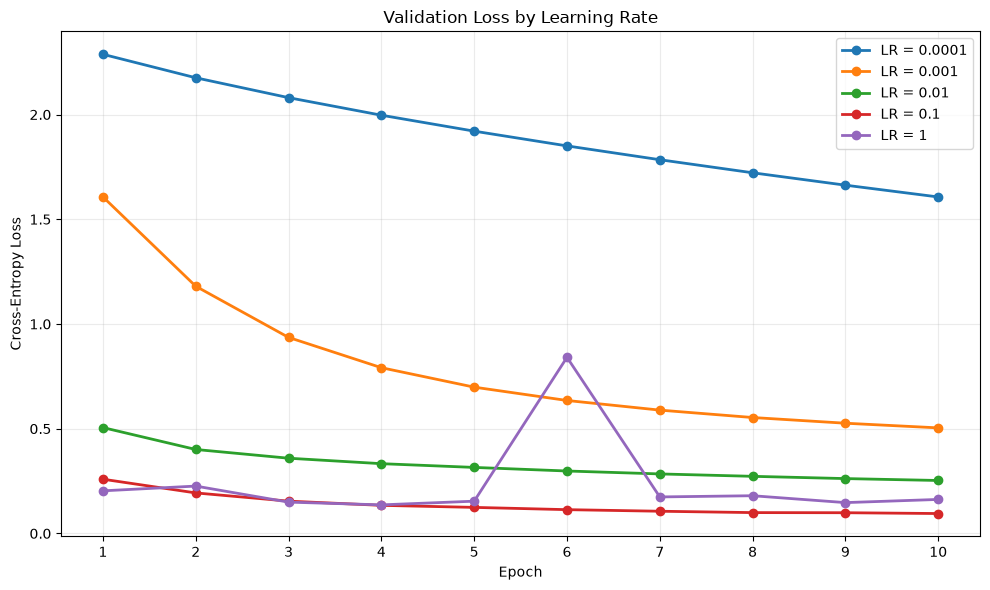

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))

for experiment in experiments:
    lr = experiment["config"]["learning_rate"]
    losses = experiment["history"]["val_loss"]
    epochs = np.arange(1, len(losses) + 1)

    ax.plot(
        epochs,
        losses,
        marker="o",
        linewidth=2,
        label=f"LR = {lr:g}",
    )

ax.set(
    title="Validation Loss by Learning Rate",
    xlabel="Epoch",
    ylabel="Cross-Entropy Loss",
)

ax.set_xticks(np.arange(1, 11))
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
plt.show()


## Generalization Gap

Generalization refers to a model's ability to perform
well on previously unseen data rather than merely
fitting its training examples.

One way to investigate generalization is to compare
training loss and validation loss.

The generalization gap is defined as:

$$
\text{Generalization Gap}
=
L_{\text{validation}} - L_{\text{training}}
$$

A positive gap indicates that the model performs worse
on validation data than on training data.

A growing gap may suggest overfitting, especially when
training loss continues to decrease while validation
loss stagnates or increases.

However, the generalization gap alone is not sufficient
to diagnose overfitting. A model may have a small gap
simply because it underfits both datasets.

In this experiment, we compare how the generalization
gap evolves across different learning rates and examine
whether differences arise from learning progress,
generalization behavior, or optimization instability.


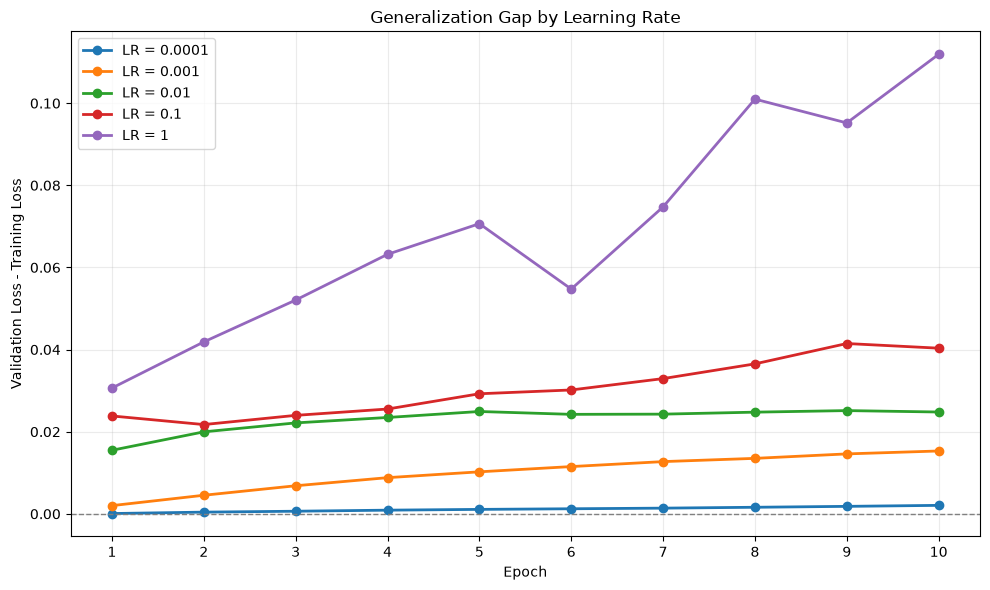

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

for experiment in experiments:
    lr = experiment["config"]["learning_rate"]

    train_loss = np.array(experiment["history"]["train_loss"])
    val_loss = np.array(experiment["history"]["val_loss"])

    gap = val_loss - train_loss
    epochs = np.arange(1, len(gap) + 1)

    ax.plot(
        epochs,
        gap,
        marker="o",
        linewidth=2,
        label=f"LR = {lr:g}",
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=1)

ax.set(
    title="Generalization Gap by Learning Rate",
    xlabel="Epoch",
    ylabel="Validation Loss - Training Loss",
)

ax.set_xticks(np.arange(1, 11))
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
plt.show()

In [9]:
assert len(experiments) == 5

for exp in experiments:
    config = exp["config"]

    assert config["model"] == "mlp"
    assert config["epochs"] == 10
    assert config["batch_size"] == 64
    assert config["hidden_dim"] == 128
    assert config["seed"] == 42

## Results and Discussion

### 1. Convergence Speed

Increasing the learning rate generally accelerated the reduction in training and validation loss up to a learning rate of 0.1.

Among the tested values, a learning rate of **0.1** achieved the fastest stable convergence and the lowest validation loss within the fixed training budget of 10 epochs.

Although models trained with learning rates of 0.001 and 0.01 showed gradual and stable convergence, they did not reach the performance of the 0.1 model within the same number of epochs.

The learning rate of 1.0 also allowed rapid learning, but its unstable loss curve makes it less reliable.

### 2. Optimization Stability

All tested learning rates except 1.0 showed relatively smooth and stable decreases in training and validation loss.

The model trained with a learning rate of 1.0 exhibited a sudden increase in loss around the sixth epoch, followed by a substantial recovery in the following epoch.

This behavior suggests optimization instability, potentially caused by excessively large parameter updates that move the model away from a favorable region of the loss landscape.

However, the model eventually recovered, indicating that the observed instability did not result in permanent divergence.

### 3. Generalization

The generalization gap generally increased during training, although this does not necessarily indicate overfitting.

As the models learned to fit the training data more accurately, differences between training and validation loss became more apparent.

A particularly interesting observation was the model trained with a learning rate of 1.0. Despite achieving a slightly lower final training loss (0.0504) than the model with a learning rate of 0.1 (0.0546), it produced a higher validation loss (0.1623 compared with 0.0950).

Consequently, the model with a learning rate of 1.0 showed a larger final generalization gap and worse validation performance.

This demonstrates that minimizing training loss does not necessarily lead to better generalization. Although overfitting may contribute to this behavior, optimization instability is another possible explanation.

### 4. Hypothesis Evaluation

The experimental results largely supported the initial hypotheses.

As predicted, a learning rate of **0.1** achieved the lowest validation loss (0.0950) and highest validation accuracy (97.26%) among the five tested values.

The model trained with a learning rate of 0.01 converged more slowly, while smaller learning rates showed substantially slower learning within the 10-epoch budget.

The hypothesis that a learning rate of 1.0 could cause optimization instability was also supported by the sudden loss spike observed during training.

However, the model recovered afterward, demonstrating that optimization instability does not necessarily imply permanent divergence.

### 5. Limitations

The experiments were conducted using a single random seed and a fixed training budget of 10 epochs.

Consequently, the results do not establish which learning rate performs best across longer training runs or different random initializations.

Furthermore, the observed instability at a learning rate of 1.0 does not establish that this learning rate will consistently produce unstable behavior under different experimental conditions.

Additional experiments with longer training durations and multiple random seeds would be required to evaluate the robustness of these findings.